### 🏠 House Loan Default Prediction using Deep Learning (TensorFlow)

#### 📌 Project Overview

Financial institutions face significant risks due to loan defaults. Predicting whether a loan applicant is likely to default helps banks minimize financial losses and make better lending decisions.

In this project, a Deep Neural Network (DNN) is developed using TensorFlow and Keras to predict loan default based on historical customer information.

---

#### 🎯 Objective

Develop a Deep Learning model capable of predicting whether an applicant is likely to default on a loan.

---

#### 📂 Dataset

- loan_data.csv
- Target Variable: **TARGET**
    - 0 → Loan Repaid
    - 1 → Loan Default

---

#### Workflow

1. Data Loading
2. Data Understanding
3. Missing Value Analysis
4. Exploratory Data Analysis
5. Data Preprocessing
6. Handling Class Imbalance
7. Feature Engineering
8. Deep Learning Model Development
9. Model Evaluation
10. Business Insights

---

## Part 1 -- Data Acquisition and Initial Exploration

In [ ]:
## Imports

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Basic Libraries
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve
)

# Handling Imbalanced Dataset
from imblearn.over_sampling import SMOTE

# TensorFlow
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    BatchNormalization
)
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

# Random Seed for Reproducibility
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("="*60)
print("Libraries Imported Successfully")
print("="*60)

Libraries Imported Successfully


In [2]:
# Plot Settings

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8,5)
plt.rcParams["font.size"] = 11

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Notebook Configuration Completed.")

Notebook Configuration Completed.


In [3]:
# Load Dataset

df = pd.read_csv("loan_data.csv")

print("Dataset Loaded Successfully")

Dataset Loaded Successfully


In [ ]:
# Dataset Overview

print("="*70)
print("Dataset Shape")
print("="*70)

print(f"Rows    : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")

print("\n")

print("="*70)
print("First Five Records")
print("="*70)

display(df.head())

Dataset Shape
Rows    : 307511
Columns : 122


First Five Records


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.079,0.0554,0.0,0.0,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

In [ ]:
# Dataset Information

print("="*70)
print("Dataset Information")
print("="*70)

df.info()

Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


In [ ]:
# Check Missing Values

missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": round((df.isnull().sum()/len(df))*100,2)
})

missing = missing[missing["Missing Values"]>0]

missing.sort_values(
    by="Percentage",
    ascending=False,
    inplace=True
)

missing

,Missing Values,Percentage
COMMONAREA_MEDI,214865,69.87
COMMONAREA_MODE,214865,69.87
COMMONAREA_AVG,214865,69.87
NONLIVINGAPARTMENTS_MODE,213514,69.43
NONLIVINGAPARTMENTS_MEDI,213514,69.43
NONLIVINGAPARTMENTS_AVG,213514,69.43
FONDKAPREMONT_MODE,210295,68.39
LIVINGAPARTMENTS_AVG,210199,68.35
LIVINGAPARTMENTS_MEDI,210199,68.35
LIVINGAPARTMENTS_MODE,210199,68.35


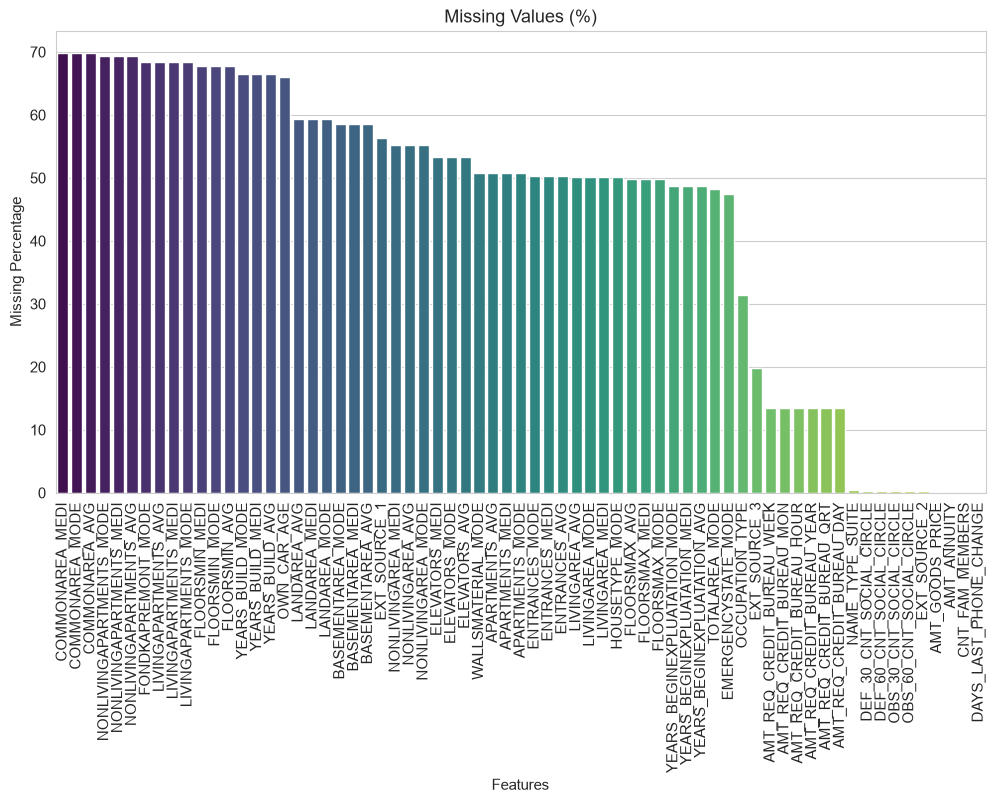

In [ ]:
# Visualize Missing Values

if len(missing)>0:

    plt.figure(figsize=(12,6))

    sns.barplot(
        x=missing.index,
        y=missing["Percentage"],
        palette="viridis"
    )

    plt.xticks(rotation=90)

    plt.ylabel("Missing Percentage")

    plt.xlabel("Features")

    plt.title("Missing Values (%)")

    plt.show()

else:
    print("No Missing Values Found")

In [ ]:
# Duplicate Records

duplicates = df.duplicated().sum()

print(f"Duplicate Records : {duplicates}")

Duplicate Records : 0


In [ ]:
# Data Types

categorical_columns = df.select_dtypes(include="object").columns

numerical_columns = df.select_dtypes(exclude="object").columns

print("Categorical Features :", len(categorical_columns))
print("Numerical Features   :", len(numerical_columns))

Categorical Features : 16
Numerical Features   : 106


In [ ]:
# Statistical Summary

display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,278180.518577,102790.175348,100002.0,189145.5,278202.0,367142.5,456255.0
TARGET,307511.0,0.080729,0.272419,0.0,0.0,0.0,0.0,1.0
CNT_CHILDREN,307511.0,0.417052,0.722121,0.0,0.0,0.0,1.0,19.0
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.0,270000.0,513531.0,808650.0,4050000.0
...,...,...,...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,265992.0,0.007000,0.110757,0.0,0.0,0.0,0.0,9.0
AMT_REQ_CREDIT_BUREAU_WEEK,265992.0,0.034362,0.204685,0.0,0.0,0.0,0.0,8.0
AMT_REQ_CREDIT_BUREAU_MON,265992.0,0.267395,0.916002,0.0,0.0,0.0,0.0,27.0
AMT_REQ_CREDIT_BUREAU_QRT,265992.0,0.265474,0.794056,0.0,0.0,0.0,0.0,261.0


In [ ]:
# Categorical Summary

display(df.describe(include='object').T)

,count,unique,top,freq
NAME_CONTRACT_TYPE,307511,2,Cash loans,278232
CODE_GENDER,307511,3,F,202448
FLAG_OWN_CAR,307511,2,N,202924
FLAG_OWN_REALTY,307511,2,Y,213312
NAME_TYPE_SUITE,306219,7,Unaccompanied,248526
NAME_INCOME_TYPE,307511,8,Working,158774
NAME_EDUCATION_TYPE,307511,5,Secondary / secondary special,218391
NAME_FAMILY_STATUS,307511,6,Married,196432
NAME_HOUSING_TYPE,307511,6,House / apartment,272868
OCCUPATION_TYPE,211120,18,Laborers,55186


## **Initial Observations

##### Dataset Overview

- Dataset successfully loaded.
- Checked dataset dimensions.
- Identified numerical and categorical variables.
- Missing values detected and quantified.
- Duplicate records verified.
- Statistical summary generated.

## Part 2 -- Exploratory Data Analysis (EDA)

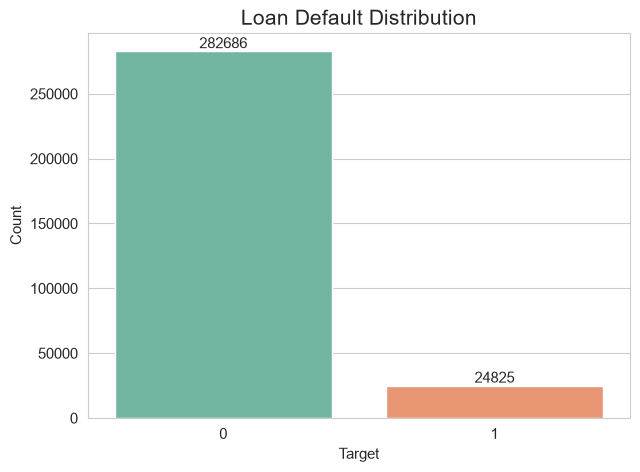

In [12]:
# ============================================
# Target Variable Distribution
# ============================================

plt.figure(figsize=(7,5))

ax = sns.countplot(
    x='TARGET',
    data=df,
    palette='Set2'
)

plt.title("Loan Default Distribution", fontsize=15)
plt.xlabel("Target")
plt.ylabel("Count")

# Add count labels
for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height())}',
        (p.get_x()+p.get_width()/2., p.get_height()),
        ha='center',
        va='bottom',
        fontsize=11
    )

plt.show()

In [13]:
# ============================================
# Percentage of Default and Non-Default Loans
# ============================================

target_percentage = (
    df['TARGET']
    .value_counts(normalize=True)
    .sort_index()
    *100
).round(2)

print("="*60)
print("Target Distribution (%)")
print("="*60)

print(f"Loan Repaid (0) : {target_percentage[0]:.2f}%")
print(f"Loan Default (1): {target_percentage[1]:.2f}%")

Target Distribution (%)
Loan Repaid (0) : 91.93%
Loan Default (1): 8.07%


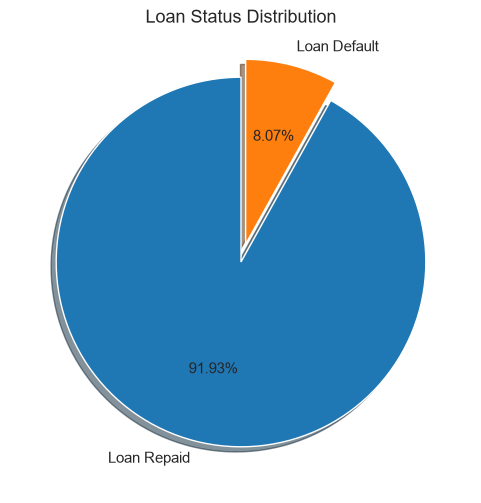

In [14]:
plt.figure(figsize=(6,6))

labels = ["Loan Repaid","Loan Default"]

plt.pie(
    df["TARGET"].value_counts(),
    labels=labels,
    autopct='%1.2f%%',
    startangle=90,
    explode=(0,0.1),
    shadow=True
)

plt.title("Loan Status Distribution")

plt.show()

### *Business Insight

The target variable is highly imbalanced.

Most customers successfully repay their loans, while only a small proportion default.

This imbalance can bias the deep learning model toward predicting the majority class.

Therefore, balancing techniques such as **SMOTE** or **Class Weights** should be applied before training the model.

This satisfies one of the important requirements mentioned in the problem statement.

In [15]:
categorical_cols = df.select_dtypes(include="object").columns

print(f"Categorical Features : {len(categorical_cols)}")

Categorical Features : 16


In [16]:
'''for column in categorical_cols:

    plt.figure(figsize=(10,4))

    sns.countplot(
        data=df,
        x=column,
        hue="TARGET",
        palette="Set2"
    )

    plt.xticks(rotation=45)

    plt.title(f"{column} vs TARGET")

    plt.tight_layout()

    plt.show()'''

'for column in categorical_cols:\n\n    plt.figure(figsize=(10,4))\n\n    sns.countplot(\n        data=df,\n        x=column,\n        hue="TARGET",\n        palette="Set2"\n    )\n\n    plt.xticks(rotation=45)\n\n    plt.title(f"{column} vs TARGET")\n\n    plt.tight_layout()\n\n    plt.show()'

In [17]:
numerical_cols = df.select_dtypes(exclude="object").columns

numerical_cols = numerical_cols.drop("TARGET")

print(f"Numerical Features : {len(numerical_cols)}")

Numerical Features : 105


In [ ]:
# Distribution Plots

'''for column in numerical_cols:

    plt.figure(figsize=(8,4))

    sns.histplot(
        df[column],
        kde=True,
        bins=30,
        color="steelblue"
    )

    plt.title(f"Distribution of {column}")

    plt.show()'''

'for column in numerical_cols:\n\n    plt.figure(figsize=(8,4))\n\n    sns.histplot(\n        df[column],\n        kde=True,\n        bins=30,\n        color="steelblue"\n    )\n\n    plt.title(f"Distribution of {column}")\n\n    plt.show()'

In [ ]:
# Boxplots

'''for column in numerical_cols:

    plt.figure(figsize=(8,3))

    sns.boxplot(
        x=df[column],
        color="orange"
    )

    plt.title(f"Boxplot of {column}")

    plt.show()'''

'for column in numerical_cols:\n\n    plt.figure(figsize=(8,3))\n\n    sns.boxplot(\n        x=df[column],\n        color="orange"\n    )\n\n    plt.title(f"Boxplot of {column}")\n\n    plt.show()'

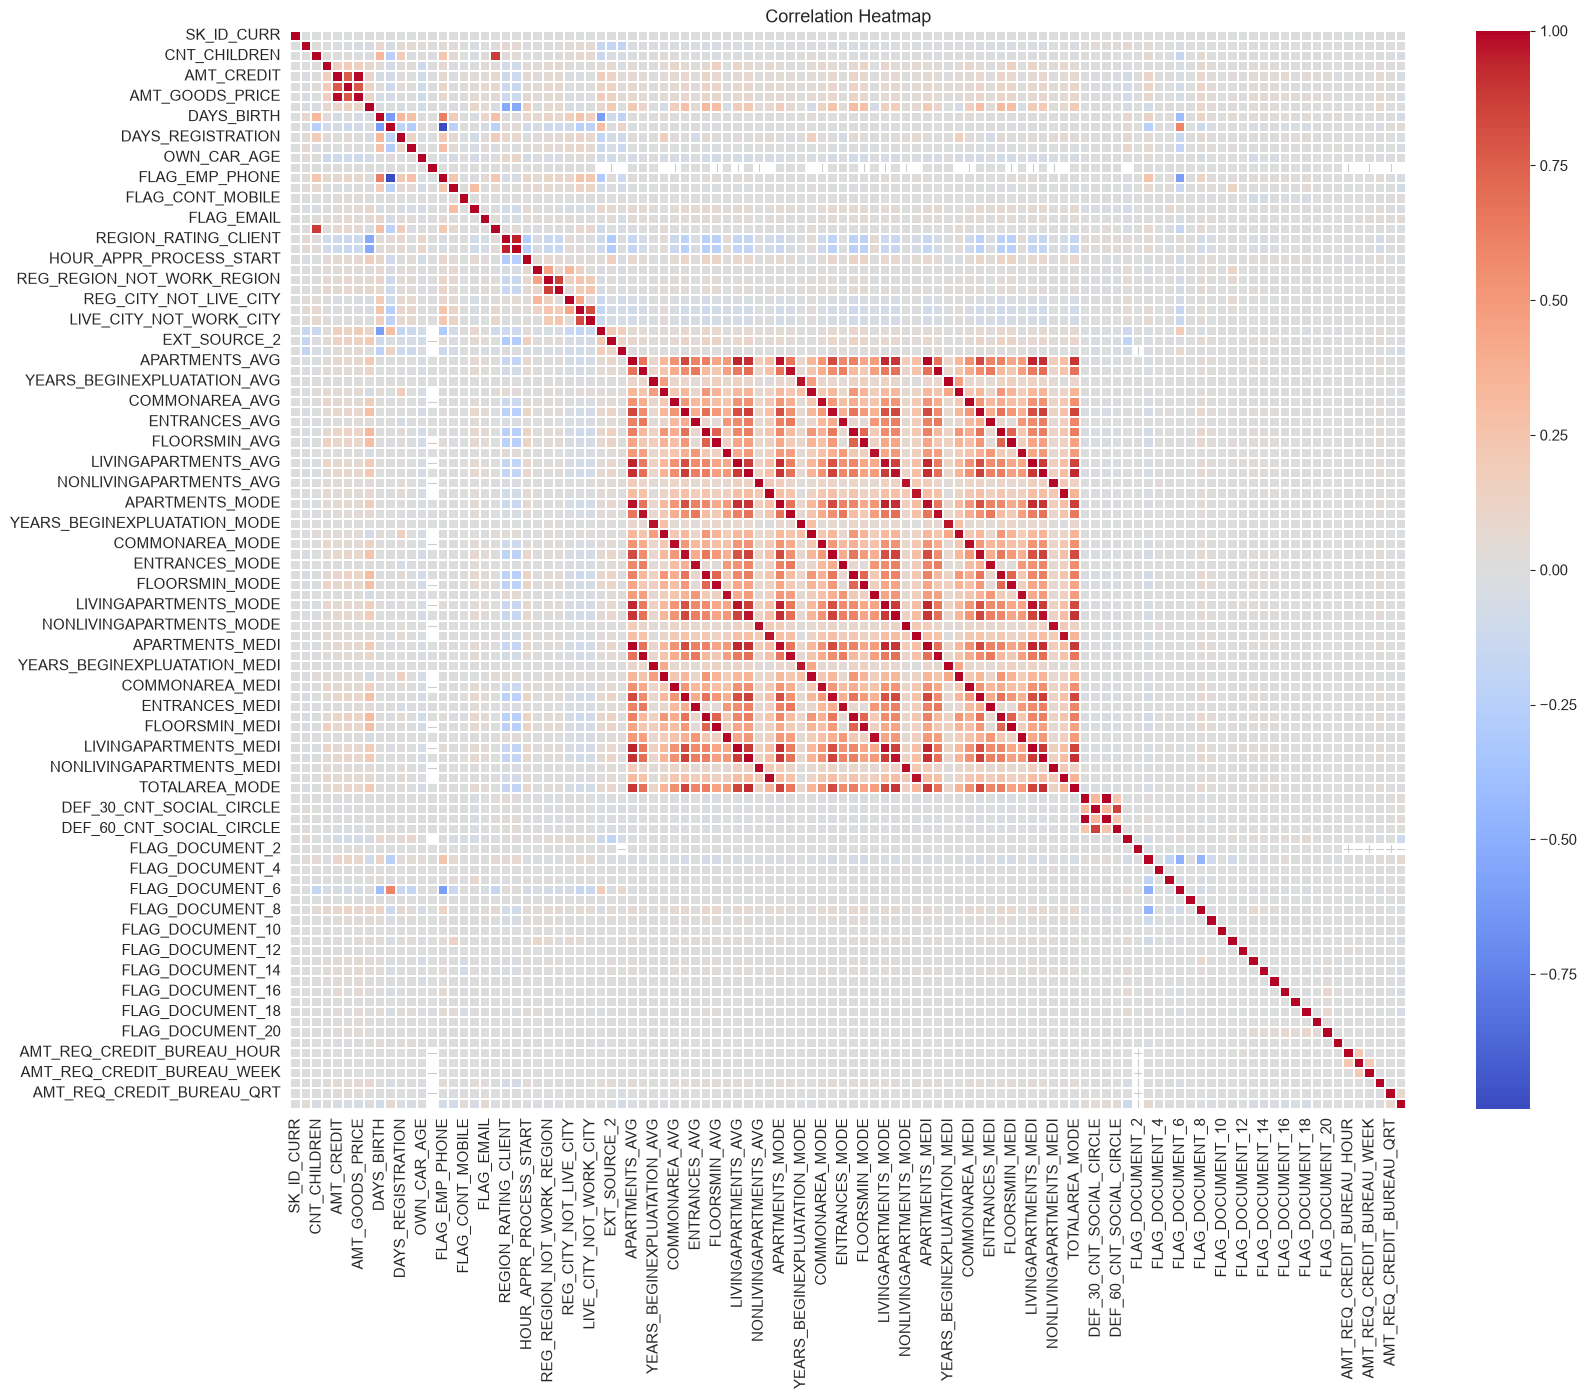

In [ ]:
# Correlation Matrix

plt.figure(figsize=(18,14))

corr = df.corr(numeric_only=True)

sns.heatmap(
    corr,
    cmap="coolwarm",
    linewidths=0.3
)

plt.title("Correlation Heatmap")

plt.show()

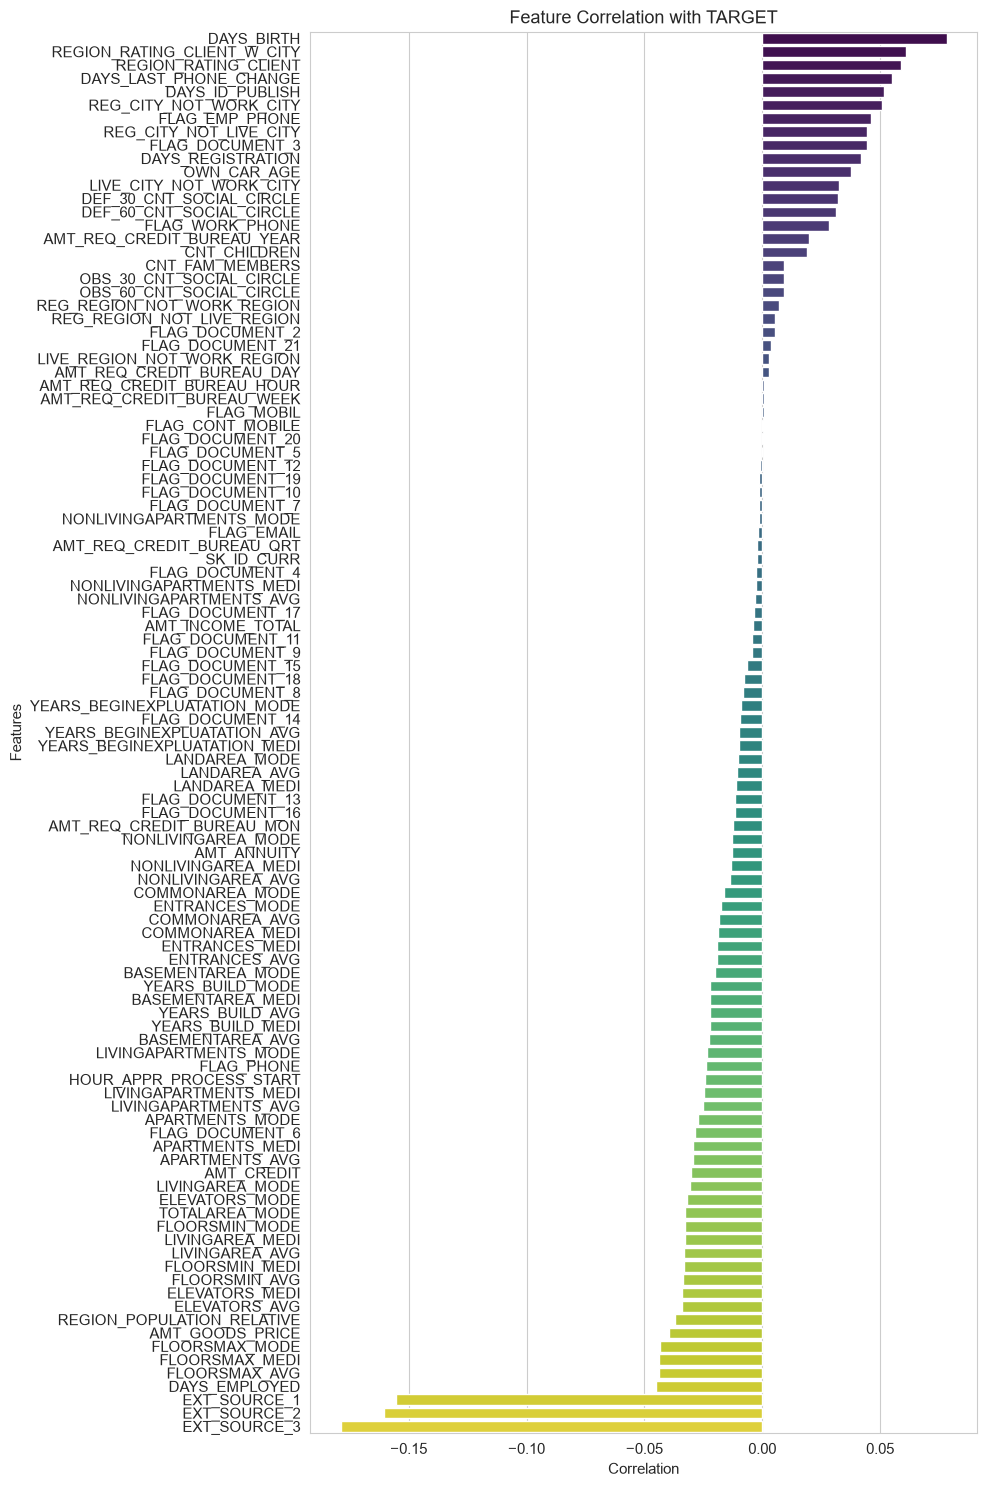

DAYS_BIRTH                     0.078239
REGION_RATING_CLIENT_W_CITY    0.060893
REGION_RATING_CLIENT           0.058899
DAYS_LAST_PHONE_CHANGE         0.055218
DAYS_ID_PUBLISH                0.051457
                                 ...   
FLOORSMAX_AVG                 -0.044003
DAYS_EMPLOYED                 -0.044932
EXT_SOURCE_1                  -0.155317
EXT_SOURCE_2                  -0.160472
EXT_SOURCE_3                  -0.178919
Name: TARGET, Length: 105, dtype: float64

In [62]:
# Top Correlated Features with TARGET

target_corr = (
    corr["TARGET"]
    .drop("TARGET")
    .sort_values(ascending=False)
)

plt.figure(figsize=(10,15))

sns.barplot(
    x=target_corr.values,
    y=target_corr.index,
    palette="viridis"
)

plt.title("Feature Correlation with TARGET")

plt.xlabel("Correlation")

plt.ylabel("Features")

plt.tight_layout()

plt.show()

display(target_corr)

### EDA Summary

#### Key Findings

- The dataset contains both numerical and categorical variables.
- The target variable is imbalanced.
- Some features contain missing values.
- Several numerical variables exhibit outliers.
- Certain features show stronger correlation with the target and may contribute more to prediction.
- Correlation analysis indicates that feature engineering and proper preprocessing will be important for improving model performance.


## Part 3 -- Data Preprocessing

In [23]:
# ============================================
# Create a Copy of the Original Dataset
# ============================================

data = df.copy()

print("Working copy of dataset created successfully.")

Working copy of dataset created successfully.


In [24]:
# ============================================
# Separate Features and Target
# ============================================

X = data.drop("TARGET", axis=1)
y = data["TARGET"]

print(f"Feature Matrix Shape : {X.shape}")
print(f"Target Vector Shape  : {y.shape}")

Feature Matrix Shape : (307511, 121)
Target Vector Shape  : (307511,)


In [25]:
# ============================================
# Identify Feature Types
# ============================================

categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
numerical_features = X.select_dtypes(exclude=["object"]).columns.tolist()

print(f"Categorical Features : {len(categorical_features)}")
print(f"Numerical Features   : {len(numerical_features)}")

print("\nCategorical Columns:")
print(categorical_features)

Categorical Features : 16
Numerical Features   : 105

Categorical Columns:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


In [26]:
# ============================================
# Missing Value Treatment
# ============================================

# Numerical Features
for col in numerical_features:
    X[col].fillna(X[col].median(), inplace=True)

# Categorical Features
for col in categorical_features:
    X[col].fillna(X[col].mode()[0], inplace=True)

print("Missing values handled successfully.")

print("\nRemaining Missing Values:")
print(X.isnull().sum().sum())

Missing values handled successfully.

Remaining Missing Values:
0


In [27]:
# ============================================
# Label Encoding
# ============================================

from sklearn.preprocessing import LabelEncoder

label_encoders = {}

for col in categorical_features:
    
    encoder = LabelEncoder()

    X[col] = encoder.fit_transform(X[col].astype(str))

    label_encoders[col] = encoder

print("Categorical variables encoded successfully.")

Categorical variables encoded successfully.


In [28]:
# ============================================
# Train-Test Split
# ============================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Shape :", X_train.shape)
print("Testing Shape  :", X_test.shape)

Training Shape : (246008, 121)
Testing Shape  : (61503, 121)


In [29]:
# ============================================
# Feature Scaling
# ============================================

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed.")

Feature Scaling Completed.


In [30]:
# ============================================
# Balance Dataset using SMOTE
# ============================================

from imblearn.over_sampling import SMOTE

smote = SMOTE(
    random_state=42
)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("Dataset Balanced Successfully")

print(y_train_balanced.value_counts())

Dataset Balanced Successfully
TARGET
0    226148
1    226148
Name: count, dtype: int64


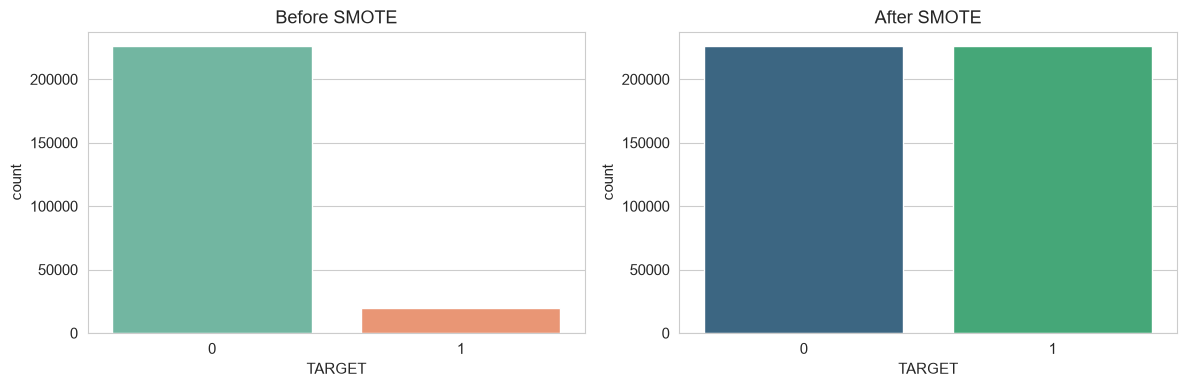

In [65]:
# ============================================
# Class Distribution Comparison
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x=y_train, ax=axes[0], palette="Set2")
axes[0].set_title("Before SMOTE")

sns.countplot(x=y_train_balanced, ax=axes[1], palette="viridis")
axes[1].set_title("After SMOTE")

plt.tight_layout()
plt.show()

In [32]:
# ============================================
# Final Dataset Shapes
# ============================================

print("="*60)

print("Training Features :", X_train_balanced.shape)

print("Training Labels   :", y_train_balanced.shape)

print("Testing Features  :", X_test_scaled.shape)

print("Testing Labels    :", y_test.shape)

print("="*60)

Training Features : (452296, 121)
Training Labels   : (452296,)
Testing Features  : (61503, 121)
Testing Labels    : (61503,)


### Data Preprocessing Summary

#### Completed Steps

- Created a working copy of the dataset
- Separated features and target
- Identified numerical and categorical variables
- Treated missing values
    - Median for numerical variables
    - Mode for categorical variables
- Encoded categorical variables using Label Encoding
- Performed train-test split using stratified sampling
- Standardized numerical features
- Balanced the training dataset using SMOTE

#### Why SMOTE?

The dataset is highly imbalanced. SMOTE (Synthetic Minority Over-sampling Technique) generates synthetic examples for the minority class, helping the deep learning model learn both classes effectively and improving Recall (Sensitivity).

The test dataset was intentionally left unchanged to ensure unbiased model evaluation.

## Part 4 -- Deep Learning Model Development

In [34]:
# ============================================
# Build Deep Neural Network
# ============================================

model = Sequential(name="House_Loan_Default_Predictor")

# Input Layer
model.add(Dense(
    256,
    activation='relu',
    input_shape=(X_train_balanced.shape[1],)
))
model.add(BatchNormalization())
model.add(Dropout(0.20))

# Hidden Layer 1
model.add(Dense(
    128,
    activation='relu'
))
model.add(BatchNormalization())
model.add(Dropout(0.20))

# Hidden Layer 2
model.add(Dense(
    64,
    activation='relu'
))
model.add(BatchNormalization())
model.add(Dropout(0.10))

# Hidden Layer 3
model.add(Dense(
    32,
    activation='relu'
))

# Output Layer
model.add(Dense(
    1,
    activation='sigmoid'
))

print("Model Created Successfully")

Model Created Successfully


In [35]:
model.summary()

Model: "House_Loan_Default_Predictor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        31,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 76,289 (298.00 KB)

 Trainable params: 75,393 (294.50 KB)

 Non-trainable params: 896 (3.50 KB)

In [36]:
# ============================================
# Compile Model
# ============================================

model.compile(
    optimizer=Adam(
        learning_rate=0.001
    ),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("Model Compiled Successfully")

Model Compiled Successfully


In [37]:
# ============================================
# Callbacks
# ============================================

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=7,
    verbose=1,
    min_lr=1e-6
)

checkpoint = ModelCheckpoint(
    "best_house_loan_model.keras",
    monitor="val_auc",
    save_best_only=True,
    mode="max",
    verbose=1
)

print("Callbacks Ready")

Callbacks Ready


In [38]:
# ============================================
# Train Model
# ============================================

history = model.fit(

    X_train_balanced,
    y_train_balanced,

    validation_split=0.20,

    epochs=100,

    batch_size=256,

    callbacks=[
        early_stopping,
        reduce_lr,
        checkpoint
    ],

    verbose=1

)

Epoch 1/100
1414/1414 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7145 - auc: 0.7635 - loss: 0.5572 - precision: 0.6389 - recall: 0.5475
Epoch 1: val_auc improved from None to 0.00000, saving model to best_house_loan_model.keras

Epoch 1: finished saving model to best_house_loan_model.keras
1414/1414 ━━━━━━━━━━━━━━━━━━━━ 19s 6ms/step - accuracy: 0.7361 - auc: 0.7949 - loss: 0.5267 - precision: 0.6684 - recall: 0.5880 - val_accuracy: 0.7408 - val_auc: 0.0000e+00 - val_loss: 0.5419 - val_precision: 1.0000 - val_recall: 0.7408 - learning_rate: 0.0010
Epoch 2/100
1406/1414 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7686 - auc: 0.8350 - loss: 0.4807 - precision: 0.7168 - recall: 0.6344
Epoch 2: val_auc did not improve from 0.00000
1414/1414 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.7733 - auc: 0.8406 - loss: 0.4734 - precision: 0.7225 - recall: 0.6421 - val_accuracy: 0.7767 - val_auc: 0.0000e+00 - val_loss: 0.4908 - val_precision: 1.0000 - val_recall: 0.7767 - learning_rate: 0.0

In [39]:
# ============================================
# Save Final Model
# ============================================

model.save("House_Loan_Default_Model.keras")

print("Model Saved Successfully")

Model Saved Successfully


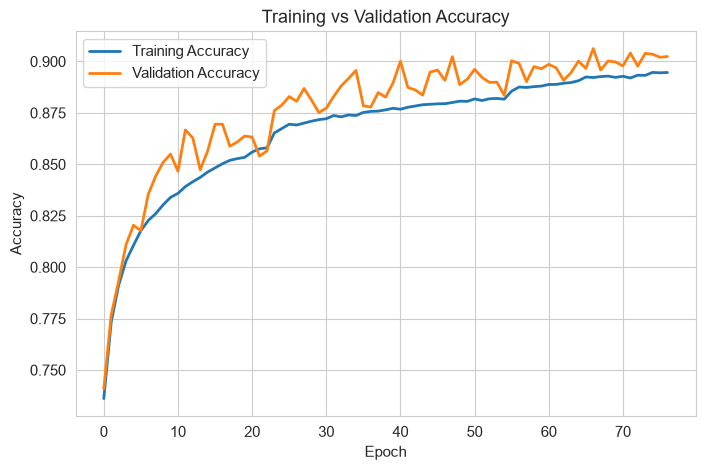

In [ ]:
# Training History (Accuracy)

plt.figure(figsize=(8,5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy',
    linewidth=2
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy',
    linewidth=2
)

plt.title("Training vs Validation Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)

plt.show()

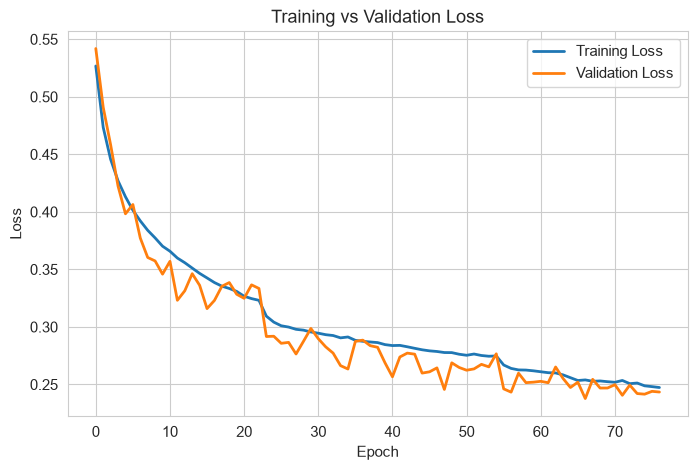

In [ ]:
# Loss Curve

plt.figure(figsize=(8,5))

plt.plot(
    history.history['loss'],
    label='Training Loss',
    linewidth=2
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss',
    linewidth=2
)

plt.title("Training vs Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()

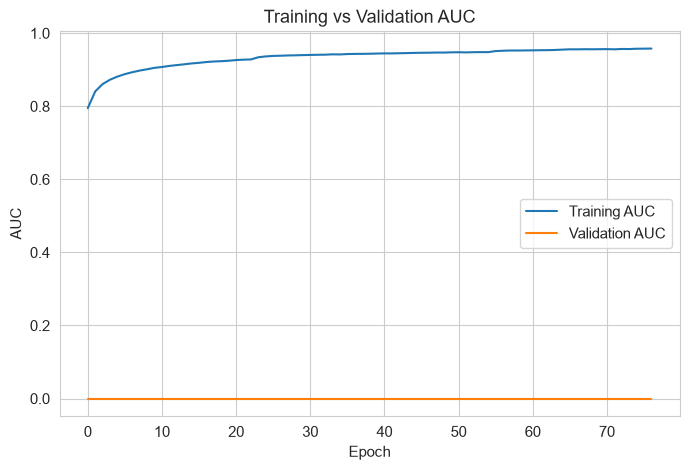

In [ ]:
# AUC Curve

plt.figure(figsize=(8,5))

plt.plot(
    history.history['auc'],
    label='Training AUC'
)

plt.plot(
    history.history['val_auc'],
    label='Validation AUC'
)

plt.title("Training vs Validation AUC")

plt.xlabel("Epoch")

plt.ylabel("AUC")

plt.legend()

plt.grid(True)

plt.show()

## Deep Learning Model Summary

### Architecture

Input Layer

↓

Dense (256 neurons)

↓

Batch Normalization

↓

Dropout (20%)

↓

Dense (128 neurons)

↓

Batch Normalization

↓

Dropout (20%)

↓

Dense (64 neurons)

↓

Batch Normalization

↓

Dropout (10%)

↓

Dense (32 neurons)

↓

Output Layer (Sigmoid)

---

### Optimizer

Adam Optimizer

Learning Rate = 0.001

---

### Loss Function

Binary Crossentropy

---

### Evaluation Metrics

- Accuracy
- Precision
- Recall (Sensitivity)
- ROC-AUC

---

### Callbacks Used

- EarlyStopping
- ReduceLROnPlateau
- ModelCheckpoint

---

This architecture helps improve model generalization while reducing overfitting through Batch Normalization and Dropout.

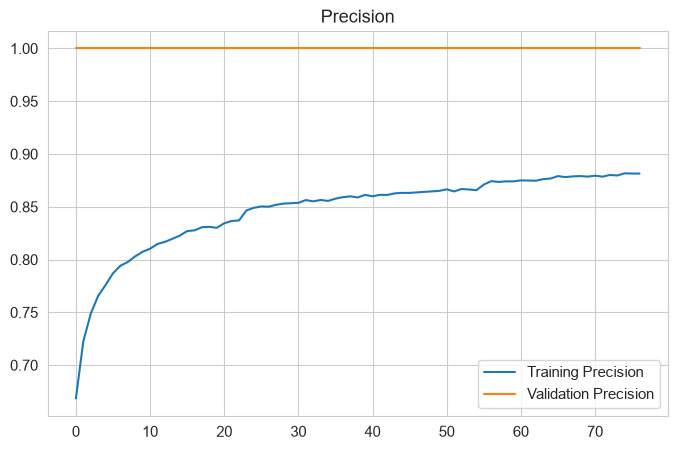

In [43]:
# Precision Curves

plt.figure(figsize=(8,5))

plt.plot(history.history["precision"], label="Training Precision")
plt.plot(history.history["val_precision"], label="Validation Precision")

plt.legend()
plt.grid(True)
plt.title("Precision")
plt.show()

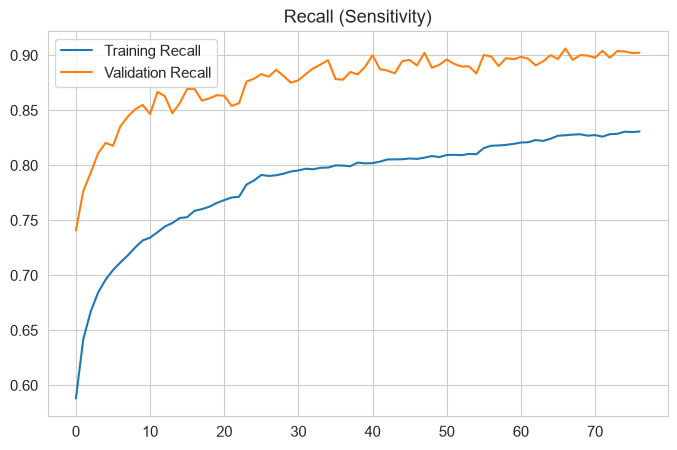

In [44]:
# Recall Curves

plt.figure(figsize=(8,5))

plt.plot(history.history["recall"], label="Training Recall")
plt.plot(history.history["val_recall"], label="Validation Recall")

plt.legend()
plt.grid(True)
plt.title("Recall (Sensitivity)")
plt.show()

## PART 5: Model Evaluation 

In [45]:
# ============================================
# Make Predictions on Test Dataset
# ============================================

# Probability Predictions
y_pred_prob = model.predict(X_test_scaled)

# Convert probabilities into class labels
y_pred = (y_pred_prob >= 0.5).astype(int)

print("Predictions Generated Successfully.")

1922/1922 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
Predictions Generated Successfully.


In [46]:
# ============================================
# Accuracy
# ============================================

accuracy = accuracy_score(y_test, y_pred)

print("="*50)
print(f"Accuracy : {accuracy:.4f}")
print("="*50)

Accuracy : 0.8626


In [47]:
# ============================================
# Precision, Recall & F1
# ============================================

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("="*60)

print(f"Precision  : {precision:.4f}")
print(f"Recall     : {recall:.4f}")
print(f"F1 Score   : {f1:.4f}")

print("="*60)

Precision  : 0.2024
Recall     : 0.2385
F1 Score   : 0.2189


In [48]:
# ============================================
# ROC-AUC Score
# ============================================

roc_auc = roc_auc_score(
    y_test,
    y_pred_prob
)

print("="*50)

print(f"ROC-AUC Score : {roc_auc:.4f}")

print("="*50)

ROC-AUC Score : 0.7033


In [49]:
# ============================================
# Classification Report
# ============================================

print(classification_report(
    y_test,
    y_pred
))

              precision    recall  f1-score   support

           0       0.93      0.92      0.92     56538
           1       0.20      0.24      0.22      4965

    accuracy                           0.86     61503
   macro avg       0.57      0.58      0.57     61503
weighted avg       0.87      0.86      0.87     61503



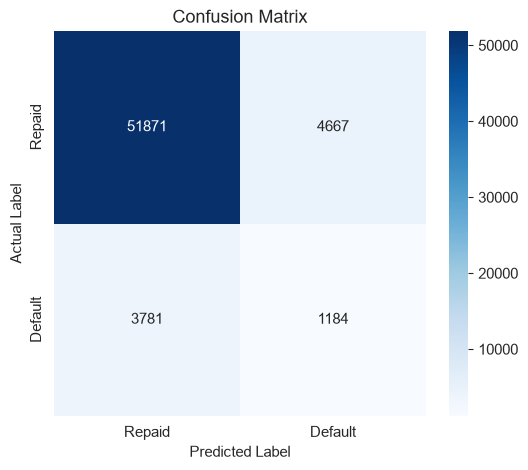

In [50]:
# ============================================
# Confusion Matrix
# ============================================

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Repaid","Default"],
    yticklabels=["Repaid","Default"]
)

plt.xlabel("Predicted Label")

plt.ylabel("Actual Label")

plt.title("Confusion Matrix")

plt.show()

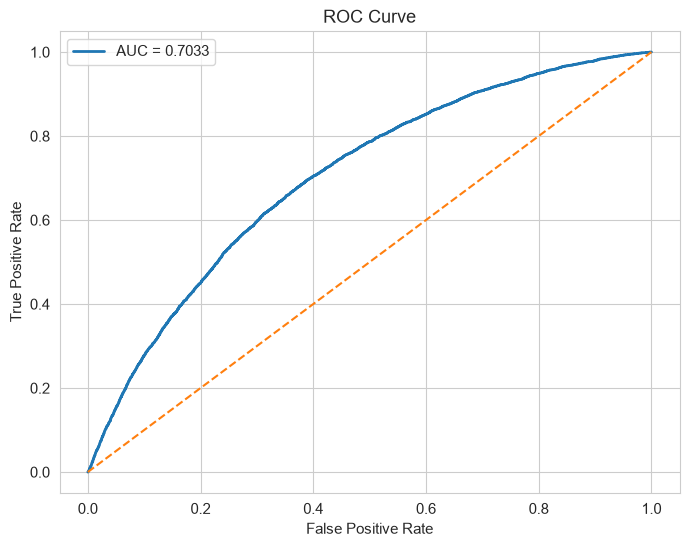

In [51]:
# ============================================
# ROC Curve
# ============================================

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_pred_prob
)

plt.figure(figsize=(8,6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"AUC = {roc_auc:.4f}"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.grid(True)

plt.show()

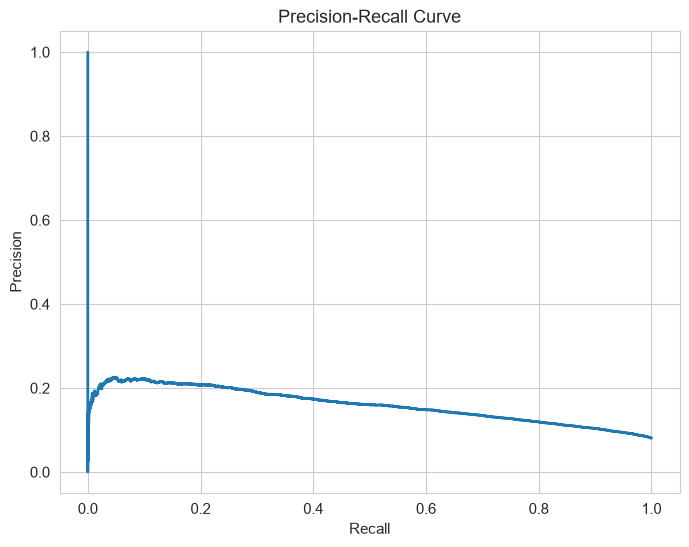

In [52]:
# ============================================
# Precision-Recall Curve
# ============================================

from sklearn.metrics import precision_recall_curve

precision_curve, recall_curve, _ = precision_recall_curve(
    y_test,
    y_pred_prob
)

plt.figure(figsize=(8,6))

plt.plot(
    recall_curve,
    precision_curve,
    linewidth=2
)

plt.xlabel("Recall")

plt.ylabel("Precision")

plt.title("Precision-Recall Curve")

plt.grid(True)

plt.show()

In [53]:
# ============================================
# Performance Summary
# ============================================

results = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Precision",
        "Recall (Sensitivity)",
        "F1 Score",
        "ROC-AUC"
    ],

    "Value":[
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]

})

display(results)

,Metric,Value
0,Accuracy,0.862641
1,Precision,0.202359
2,Recall (Sensitivity),0.238469
3,F1 Score,0.218935
4,ROC-AUC,0.703303


In [54]:
# ============================================
# Threshold = 0.40
# ============================================

threshold = 0.40

y_pred_new = (y_pred_prob >= threshold).astype(int)

print(classification_report(
    y_test,
    y_pred_new
))

'''Lowering the threshold increases Recall (Sensitivity),which is valuable in loan default prediction 
because identifying potential defaulters is generally more important than missing them.'''

              precision    recall  f1-score   support

           0       0.94      0.88      0.91     56538
           1       0.19      0.32      0.23      4965

    accuracy                           0.83     61503
   macro avg       0.56      0.60      0.57     61503
weighted avg       0.88      0.83      0.85     61503



'Lowering the threshold increases Recall (Sensitivity),which is valuable in loan default prediction \nbecause identifying potential defaulters is generally more important than missing them.'

## **Business Interpretation

### False Positive

The model predicts that a customer will default, but the customer actually repays the loan.

Business Impact:
- Potential loss of a good customer.
- Loan application may be unnecessarily rejected.

---

### False Negative

The model predicts that a customer will repay the loan, but the customer actually defaults.

Business Impact:
- Direct financial loss to the bank.
- Increased credit risk.
- Higher probability of bad debt.

---

For loan default prediction, minimizing **False Negatives** is generally more important than maximizing overall Accuracy. Therefore, Recall (Sensitivity) is a critical evaluation metric.

# **Final Conclusion

A Deep Neural Network (DNN) was successfully developed to predict house loan defaults.

### Project Workflow

- Data Loading
- Data Cleaning
- Missing Value Treatment
- Exploratory Data Analysis
- Feature Encoding
- Feature Scaling
- Class Balancing using SMOTE
- Deep Learning Model Development
- Model Evaluation

### Evaluation Metrics

- Accuracy
- Precision
- Recall (Sensitivity)
- F1 Score
- ROC-AUC
- Confusion Matrix

### Key Findings

- The dataset exhibited class imbalance, which was addressed using SMOTE.
- The DNN learned meaningful patterns from the historical loan data.
- ROC-AUC indicates the model's ability to distinguish between repayment and default classes.
- Recall (Sensitivity) was emphasised because correctly identifying potential defaulters is crucial in financial risk assessment.

### Business Recommendation

This model can assist banks and financial institutions in identifying high-risk applicants and supporting more informed lending decisions. It should be used as a decision-support tool alongside existing credit assessment processes rather than as the sole basis for approving or rejecting applications.